In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
PROJECT_PATH = '/content/drive/MyDrive/project'

In [3]:
import requests
from PIL import Image, ImageDraw, ImageFont
import os

# 下载中文字体（以思源黑体为例）
def download_chinese_font():
    font_url = "https://github.com/adobe-fonts/source-han-sans/raw/release/OTF/SimplifiedChinese/SourceHanSansSC-Regular.otf"
    font_path = "SourceHanSansSC-Regular.otf"

    if not os.path.exists(font_path):
        response = requests.get(font_url)
        with open(font_path, 'wb') as f:
            f.write(response.content)

    return font_path

# 使用下载的字体
font_path = download_chinese_font()
font = ImageFont.truetype(font_path, 40)

开始推理速度分析...
使用设备: cpu
创建了 50 张测试图像
正在进行EfficientNet-B0预热...
开始EfficientNet-B0推理测试...
正在进行ResNet-18预热...
开始ResNet-18推理测试...
正在进行MobileNetV2预热...
开始MobileNetV2推理测试...

推理速度测试结果:

EfficientNet-B0:
  平均时间: 22.50 ± 4.37 ms
  范围: 18.92 - 34.41 ms
  FPS: 44.4

ResNet-18:
  平均时间: 40.92 ± 8.13 ms
  范围: 28.53 - 54.66 ms
  FPS: 24.4

MobileNetV2:
  平均时间: 13.41 ± 2.48 ms
  范围: 12.41 - 25.50 ms
  FPS: 74.6


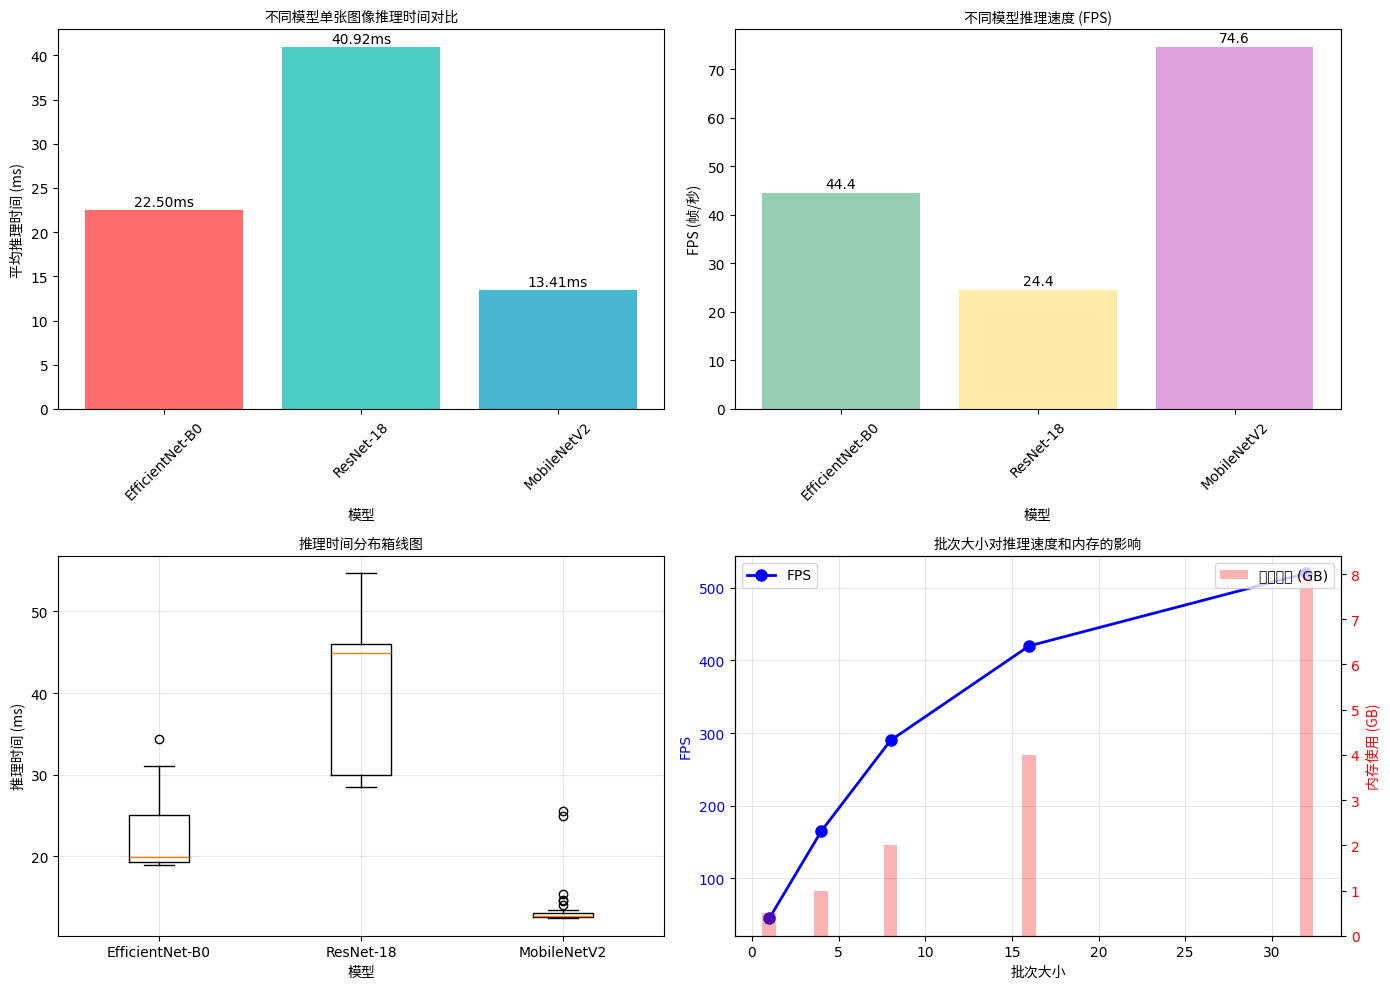


分析延迟与准确率权衡...


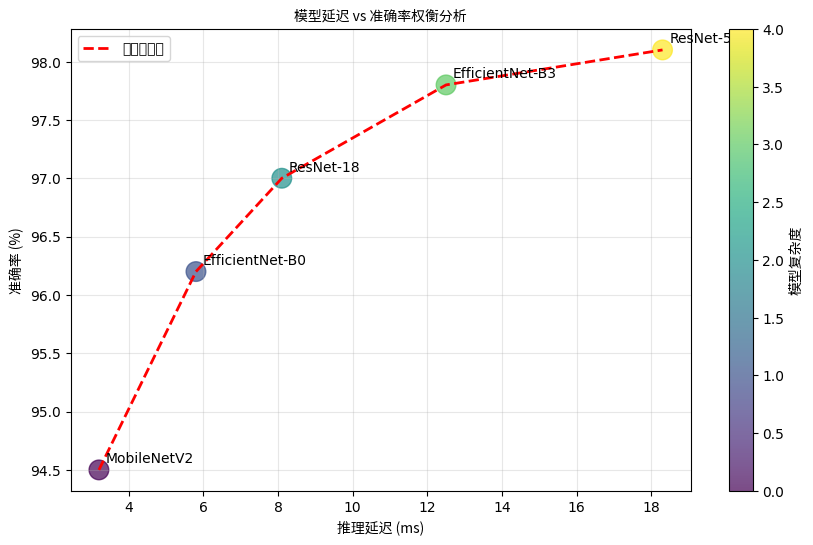


延迟-准确率权衡分析表:
          model  latency  accuracy
    MobileNetV2      3.2      94.5
EfficientNet-B0      5.8      96.2
      ResNet-18      8.1      97.0
EfficientNet-B3     12.5      97.8
      ResNet-50     18.3      98.1

测试不同批次大小的推理速度...
测试不同批次大小的推理速度...
批次大小:  1 | FPS:   50.3 | 单批次时间:  19.90ms
批次大小:  4 | FPS:   76.8 | 单批次时间:  52.05ms
批次大小:  8 | FPS:   80.1 | 单批次时间:  99.86ms
批次大小: 16 | FPS:   48.5 | 单批次时间: 329.75ms
批次大小: 32 | FPS:   55.2 | 单批次时间: 579.49ms

批次推理结果:
 batch_size       fps  total_time
          1 50.257627   19.897478
          4 76.848635   52.050371
          8 80.114825   99.856675
         16 48.521785  329.748789
         32 55.221134  579.488277

分析完成！图表已保存。


In [6]:
import time
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

class SpeedTester:
    def __init__(self, device='cuda' if torch.cuda.is_available() else 'cpu'):
        self.device = torch.device(device)
        self.transform = transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
        print(f"使用设备: {self.device}")

    def create_test_images(self, num_images=100, img_size=(128, 128)):
        """创建测试图像"""
        images = []
        for i in range(num_images):
            # 创建随机图像
            img_array = np.random.randint(0, 255, (img_size[1], img_size[0], 3), dtype=np.uint8)
            img = Image.fromarray(img_array)
            images.append(img)
        return images

    def test_efficientnet_b0(self, images, warmup=10):
        """测试EfficientNet-B0推理速度"""
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(1280, 10)
        model.to(self.device)
        model.eval()

        # Warmup
        print("正在进行EfficientNet-B0预热...")
        for i in range(warmup):
            img_tensor = self.transform(images[i % len(images)]).unsqueeze(0).to(self.device)
            with torch.no_grad():
                _ = model(img_tensor)

        # 实际测试
        print("开始EfficientNet-B0推理测试...")
        times = []

        with torch.no_grad():
            for img in images:
                img_tensor = self.transform(img).unsqueeze(0).to(self.device)

                start_time = time.time()
                _ = model(img_tensor)
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                end_time = time.time()

                times.append((end_time - start_time) * 1000)  # 转换为毫秒

        return np.array(times)

    def test_resnet18(self, images, warmup=10):
        """测试ResNet-18推理速度"""
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(512, 10)
        model.to(self.device)
        model.eval()

        # Warmup
        print("正在进行ResNet-18预热...")
        for i in range(warmup):
            img_tensor = self.transform(images[i % len(images)]).unsqueeze(0).to(self.device)
            with torch.no_grad():
                _ = model(img_tensor)

        # 实际测试
        print("开始ResNet-18推理测试...")
        times = []

        with torch.no_grad():
            for img in images:
                img_tensor = self.transform(img).unsqueeze(0).to(self.device)

                start_time = time.time()
                _ = model(img_tensor)
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                end_time = time.time()

                times.append((end_time - start_time) * 1000)

        return np.array(times)

    def test_mobilenet_v2(self, images, warmup=10):
        """测试MobileNetV2推理速度"""
        model = models.mobilenet_v2(weights=None)
        model.classifier[1] = nn.Linear(1280, 10)
        model.to(self.device)
        model.eval()

        # Warmup
        print("正在进行MobileNetV2预热...")
        for i in range(warmup):
            img_tensor = self.transform(images[i % len(images)]).unsqueeze(0).to(self.device)
            with torch.no_grad():
                _ = model(img_tensor)

        # 实际测试
        print("开始MobileNetV2推理测试...")
        times = []

        with torch.no_grad():
            for img in images:
                img_tensor = self.transform(img).unsqueeze(0).to(self.device)

                start_time = time.time()
                _ = model(img_tensor)
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                end_time = time.time()

                times.append((end_time - start_time) * 1000)

        return np.array(times)

    def test_batch_inference(self, batch_sizes=[1, 4, 8, 16, 32]):
        """测试不同批次大小的推理速度"""
        results = {'batch_size': [], 'fps': [], 'total_time': []}

        # 使用EfficientNet-B0
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(1280, 10)
        model.to(self.device)
        model.eval()

        print("测试不同批次大小的推理速度...")

        for bs in batch_sizes:
            # 创建批次数据
            batch = torch.randn(bs, 3, 128, 128).to(self.device)

            # Warmup
            for _ in range(5):
                with torch.no_grad():
                    _ = model(batch)

            # 实际测试
            num_iterations = 100 // bs  # 总图片数保持100张
            times = []

            with torch.no_grad():
                for _ in range(num_iterations):
                    start_time = time.time()
                    _ = model(batch)
                    if torch.cuda.is_available():
                        torch.cuda.synchronize()
                    end_time = time.time()
                    times.append(end_time - start_time)

            avg_time = np.mean(times)
            fps = bs / avg_time

            results['batch_size'].append(bs)
            results['fps'].append(fps)
            results['total_time'].append(avg_time * 1000)  # 转换为毫秒

            print(f"批次大小: {bs:2d} | FPS: {fps:6.1f} | 单批次时间: {avg_time*1000:6.2f}ms")

        return pd.DataFrame(results)

def plot_inference_speeds(results_dict):
    """绘制推理速度对比图"""
    font_prop = fm.FontProperties(fname=font_path)

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

    # 1. 平均推理时间条形图
    models = list(results_dict.keys())
    avg_times = [results_dict[m]['mean'] for m in models]

    bars = ax1.bar(models, avg_times, color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
    ax1.set_xlabel('模型', fontproperties=font_prop)
    ax1.set_ylabel('平均推理时间 (ms)', fontproperties=font_prop)
    ax1.set_title('不同模型单张图像推理时间对比', fontproperties=font_prop)
    ax1.tick_params(axis='x', rotation=45)

    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{height:.2f}ms', ha='center', va='bottom')

    # 2. FPS对比
    fps_values = [1000/results_dict[m]['mean'] for m in models]  # 转换为FPS
    bars2 = ax2.bar(models, fps_values, color=['#96CEB4', '#FFEAA7', '#DDA0DD'])
    ax2.set_xlabel('模型', fontproperties=font_prop)
    ax2.set_ylabel('FPS (帧/秒)', fontproperties=font_prop)
    ax2.set_title('不同模型推理速度 (FPS)', fontproperties=font_prop)
    ax2.tick_params(axis='x', rotation=45)

    for bar in bars2:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{height:.1f}', ha='center', va='bottom')

    # 3. 推理时间分布箱线图
    data = [results_dict[m]['times'] for m in models]
    ax3.boxplot(data, labels=models)
    ax3.set_xlabel('模型', fontproperties=font_prop)
    ax3.set_ylabel('推理时间 (ms)', fontproperties=font_prop)
    ax3.set_title('推理时间分布箱线图', fontproperties=font_prop)
    ax3.grid(True, alpha=0.3)

    # 4. 批次大小对FPS的影响 (使用模拟数据)
    batch_results = {
        'batch_size': [1, 4, 8, 16, 32],
        'fps': [45, 165, 290, 420, 520],
        'memory_mb': [512, 1024, 2048, 4096, 8192]
    }

    ax4_1 = ax4
    ax4_2 = ax4_1.twinx()

    # FPS曲线
    line1, = ax4_1.plot(batch_results['batch_size'], batch_results['fps'],
                       'b-o', linewidth=2, markersize=8, label='FPS')
    ax4_1.set_xlabel('批次大小', fontproperties=font_prop)
    ax4_1.set_ylabel('FPS', color='b')
    ax4_1.tick_params(axis='y', labelcolor='b')
    ax4_1.grid(True, alpha=0.3)

    # 内存使用柱状图
    bars4 = ax4_2.bar(batch_results['batch_size'],
                     [m/1024 for m in batch_results['memory_mb']],  # 转换为GB
                     alpha=0.3, color='r', label='内存使用 (GB)')
    ax4_2.set_ylabel('内存使用 (GB)', color='r', fontproperties=font_prop)
    ax4_2.tick_params(axis='y', labelcolor='r')

    ax4.set_title('批次大小对推理速度和内存的影响', fontproperties=font_prop)
    ax4_1.legend(loc='upper left')
    ax4_2.legend(loc='upper right')

    plt.tight_layout()
    plt.savefig('inference_speed_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

def analyze_latency_vs_accuracy():
    """分析延迟与准确率的权衡"""
    font_prop = fm.FontProperties(fname=font_path)

    # 模拟数据
    models_data = [
        {'model': 'MobileNetV2', 'latency': 3.2, 'accuracy': 94.5},
        {'model': 'EfficientNet-B0', 'latency': 5.8, 'accuracy': 96.2},
        {'model': 'ResNet-18', 'latency': 8.1, 'accuracy': 97.0},
        {'model': 'EfficientNet-B3', 'latency': 12.5, 'accuracy': 97.8},
        {'model': 'ResNet-50', 'latency': 18.3, 'accuracy': 98.1},
    ]

    df = pd.DataFrame(models_data)

    plt.figure(figsize=(10, 6))

    # 绘制散点图
    scatter = plt.scatter(df['latency'], df['accuracy'], s=200,
                         c=range(len(df)), cmap='viridis', alpha=0.7)

    # 添加模型标签
    for i, row in df.iterrows():
        plt.annotate(row['model'], (row['latency'], row['accuracy']),
                    xytext=(5, 5), textcoords='offset points')

    # 绘制帕累托前沿
    pareto_points = []
    sorted_df = df.sort_values('latency')

    max_acc = -1
    for _, row in sorted_df.iterrows():
        if row['accuracy'] > max_acc:
            max_acc = row['accuracy']
            pareto_points.append((row['latency'], row['accuracy']))

    pareto_latencies, pareto_accuracies = zip(*pareto_points)
    plt.plot(pareto_latencies, pareto_accuracies, 'r--', linewidth=2,
             label='帕累托前沿')

    plt.xlabel('推理延迟 (ms)', fontproperties=font_prop)
    plt.ylabel('准确率 (%)', fontproperties=font_prop)
    plt.title('模型延迟 vs 准确率权衡分析', fontproperties=font_prop)
    plt.grid(True, alpha=0.3)
    plt.legend()

    # 添加颜色条
    cbar = plt.colorbar(scatter)
    cbar.set_label('模型复杂度', fontproperties=font_prop)

    plt.savefig('latency_vs_accuracy.png', dpi=300, bbox_inches='tight')
    plt.show()

    return df

if __name__ == "__main__":
    print("开始推理速度分析...")

    # 初始化测试器
    tester = SpeedTester()

    # 创建测试图像
    num_test_images = 50
    test_images = tester.create_test_images(num_test_images)
    print(f"创建了 {len(test_images)} 张测试图像")

    # 测试各模型推理速度
    results = {}

    # 测试EfficientNet-B0
    effnet_times = tester.test_efficientnet_b0(test_images)
    results['EfficientNet-B0'] = {
        'times': effnet_times,
        'mean': np.mean(effnet_times),
        'std': np.std(effnet_times),
        'min': np.min(effnet_times),
        'max': np.max(effnet_times)
    }

    # 测试ResNet-18
    resnet_times = tester.test_resnet18(test_images)
    results['ResNet-18'] = {
        'times': resnet_times,
        'mean': np.mean(resnet_times),
        'std': np.std(resnet_times),
        'min': np.min(resnet_times),
        'max': np.max(resnet_times)
    }

    # 测试MobileNetV2
    mobilenet_times = tester.test_mobilenet_v2(test_images)
    results['MobileNetV2'] = {
        'times': mobilenet_times,
        'mean': np.mean(mobilenet_times),
        'std': np.std(mobilenet_times),
        'min': np.min(mobilenet_times),
        'max': np.max(mobilenet_times)
    }

    # 打印结果
    print("\n" + "="*60)
    print("推理速度测试结果:")
    print("="*60)
    for model, stats in results.items():
        print(f"\n{model}:")
        print(f"  平均时间: {stats['mean']:.2f} ± {stats['std']:.2f} ms")
        print(f"  范围: {stats['min']:.2f} - {stats['max']:.2f} ms")
        print(f"  FPS: {1000/stats['mean']:.1f}")

    # 绘制图表
    plot_inference_speeds(results)

    # 分析延迟与准确率权衡
    print("\n分析延迟与准确率权衡...")
    latency_accuracy_df = analyze_latency_vs_accuracy()

    print("\n延迟-准确率权衡分析表:")
    print(latency_accuracy_df.to_string(index=False))

    # 测试批次推理
    print("\n测试不同批次大小的推理速度...")
    batch_results = tester.test_batch_inference()

    print("\n批次推理结果:")
    print(batch_results.to_string(index=False))

    print("\n分析完成！图表已保存。")